# Preparación de datos para la detección de lavado de activos

**Parcial — Unidad 3 · Minería de Datos · Fase CRISP-DM: Preparación de los datos**

| | |
|---|---|
| **Proyecto** | Detección de transacciones asociadas al lavado de activos |
| **Equipo** | Glender Samuel Vargas Chipana · Jhair Anthony Josue Choquecota Jimenez · Kendell Svante Norabuena Millones · Joe Miguel Vilca Bayona |
| **Fuente** | IBM AML-Data, `LI-Small_Trans.csv`, con anomalías de calidad controladas por el equipo (`LI-Small_Trans_sucio.csv`, semilla 42) |
| **Unidad de análisis** | Una transacción |
| **Variable objetivo** | `Is Laundering` (1 = operación etiquetada como lavado) |

## Resumen

El notebook transforma una ventana de **1.020.000 transacciones** con problemas de calidad en un dataset analítico de **946.201 filas × 12 variables numéricas**, sin nulos y reproducible desde el original con una sola función (`preparar_datos`).

| Indicador | Original | Final |
|---|---:|---:|
| Filas | 1.020.000 | 946.201 |
| Columnas | 11 | 12 |
| Nulos | 160.369 | 0 |
| Duplicados exactos | 20.002 | eliminados |
| Variables no numéricas | 10 | 0 |
| Transacciones positivas | 704 (0,069 %) | 655 (0,069 %) |

La proporción de la clase positiva se mantiene: la limpieza no sesga la etiqueta.

## Contenido

| Sección | Bloque de la rúbrica | Puntos |
|---|---|---:|
| [0. Configuración y carga](#0.-Configuración-y-carga) | Evidencia inicial | 1 |
| [1. Limpieza y calidad](#1.-Limpieza-y-tratamiento-de-calidad) | Limpieza y tratamiento de calidad | 5 |
| [2. Transformación y codificación](#2.-Transformación-y-codificación) | Transformación y codificación | 4 |
| [3. Ingeniería de características](#3.-Ingeniería-de-características) | Ingeniería de características | 3 |
| [4. Selección de variables](#4.-Selección-de-variables) | Selección o reducción de variables | 2 |
| [5. Dataset en proceso](#5.-Dataset-en-proceso) | Dataset en proceso | 1 |
| [6. Pipeline reproducible](#6.-Pipeline-reproducible) | Pipeline reproducible | 2 |
| [7. Dataset final](#7.-Dataset-final) | Dataset final preparado | 2 |
| [8. Conclusiones](#8.-Conclusiones) | Conclusión técnica | — |

## Flujo de datos

```
datos/00_fuente      LI-Small_Trans_sucio.csv   fuente inmutable (no se modifica)
      │  ventana de 1.020.000 filas
      ▼
datos/01_original    dataset_original.csv       entregable 1
      │  limpieza · tipos · codificación · escalado · variables nuevas
      ▼
datos/02_proceso     dataset_proceso.csv        entregable 2
      │  selección de variables
      ▼
datos/03_final       dataset_final.csv          entregable 3
```

En Colab, las tres salidas se guardan en `MyDrive/MineriaData/salida/`.

---
## 0. Configuración y carga

### 0.1 Entorno y parámetros

Todos los parámetros que afectan al resultado están en esta celda.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})

try:                                        # en Colab se monta Drive; en local no aplica
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# Ventana de trabajo: el CSV está ordenado por tiempo y sus primeros minutos concentran un volumen anómalo.
# Se leen dos bloques completos del tramo medio para cubrir las 24 horas y más casos positivos.
SALTAR = 3_060_000
N_FILAS = 1_020_000

RUTA_DRIVE = Path("/content/drive/MyDrive/MineriaData/LI-Small_Trans_sucio.csv")
if RUTA_DRIVE.exists():                     # Colab
    RUTA = RUTA_DRIVE
    DESTINO = dict.fromkeys(("original", "proceso", "final"), RUTA_DRIVE.parent / "salida")
else:                                       # repositorio local
    RAIZ = Path.cwd() if (Path.cwd() / "datos").exists() else Path.cwd().parent
    DATOS = RAIZ / "datos"
    RUTA = DATOS / "00_fuente" / "LI-Small_Trans_sucio.csv"
    DESTINO = {"original": DATOS / "01_original",
               "proceso":  DATOS / "02_proceso",
               "final":    DATOS / "03_final"}

assert RUTA.exists(), f"No se encuentra la fuente: {RUTA.resolve()}"
for carpeta in DESTINO.values():
    carpeta.mkdir(parents=True, exist_ok=True)

print(f"pandas {pd.__version__} · numpy {np.__version__}")
print(f"Fuente: {RUTA.name} ({RUTA.stat().st_size / 1e6:,.0f} MB)")

pandas 3.1.1 · numpy 2.5.4
Fuente: LI-Small_Trans_sucio.csv (663 MB)


### 0.2 Carga del dataset original

La fuente completa se conserva intacta. `df_original` es la ventana de trabajo leída **sin forzar tipos**, para que los problemas de formato queden visibles; `df_proceso` parte como copia y recibe todas las transformaciones.

In [2]:
df_original = pd.read_csv(RUTA, skiprows=range(1, 1 + SALTAR), nrows=N_FILAS, low_memory=False)
df_proceso = df_original.copy()

df_original.to_csv(DESTINO["original"] / "dataset_original.csv", index=False)   # entregable 1
print(f"Ventana cargada: {df_original.shape[0]:,} filas × {df_original.shape[1]} columnas")

Ventana cargada: 1,020,000 filas × 11 columnas


### 0.3 Evidencia inicial

In [3]:
display(df_original.head())

perfil = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "nulos": df_original.isna().sum(),
    "% nulos": (100 * df_original.isna().mean()).round(2),
    "valores distintos": df_original.nunique(),
})
display(perfil)

print(f"Dimensiones:        {df_original.shape}")
print(f"Nulos totales:      {int(df_original.isna().sum().sum()):,}")
print(f"Duplicados exactos: {int(df_original.duplicated().sum()):,}")

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/04 13:22,0123807,811EFB390,NaN,81B8AC220,3342.26,US Dollar,3342.26,US Dollar,Cheque,0
1,2022/09/04 13:17,0123807,811EFB390,018747,81B8AC220,5604.04,US Dollar,5604.04,US Dollar,Credit Card,0
2,2022/09/04 13:16,070,10042B660,0074853,81B9F6110,62961.10,US Dollar,62961.10,US Dollar,Cheque,0
3,2022/09/04 13:03,0221024,817C39630,0070701,81B15C870,2268.05,US Dollar,2268.05,US,Cheque,0
4,2022/09/04 13:18,0221024,817C39630,0070701,81B15C870,2569.93,US Dollar,2569.93,US Dollar,Credit Card,0


,tipo,nulos,% nulos,valores distintos
Timestamp,str,6653,0.650,7903
From Bank,str,13548,1.330,2225
Account,str,0,0.000,210286
To Bank,str,13538,1.330,2306
Account.1,str,0,0.000,297535
Amount Received,str,27404,2.690,459617
Receiving Currency,str,19813,1.940,84
Amount Paid,str,27220,2.670,464475
Payment Currency,str,19301,1.890,84
Payment Format,str,32892,3.220,38


Dimensiones:        (1020000, 11)
Nulos totales:      160,369


Duplicados exactos: 20,002


**Diagnóstico.** Diez de las once columnas llegan como texto. Montos (`Amount Received/Paid`) y bancos (`From/To Bank`) deberían ser numéricos, pero mezclan símbolos (`$`), coma decimal europea (`4.723,06`) y marcas de faltante (`?`, `-`). Además hay:

- nulos reales y nulos disfrazados como texto;
- filas duplicadas;
- categorías con varias grafías (`Cheque`, `CHEQUE`, ` cheque `, `CHE`);
- montos negativos y extremos;
- fechas en formatos mezclados o inválidas;
- cuentas con espacios o en minúsculas.

---
## 1. Limpieza y tratamiento de calidad

Cada paso es una función pura (`df → df`) que se reutiliza sin cambios en el pipeline de la sección 6.

### 1.1 Valores nulos

In [4]:
TOKENS_NULOS = ["?", "-", "", "N/A", "n/a", "NA", "null", "NULL", "None", "nan"]

def reporte_nulos(df: pd.DataFrame) -> pd.DataFrame:
    n = df.isna().sum()
    return pd.DataFrame({"nulos": n, "%": (100 * n / len(df)).round(2)})

def limpiar_nulos(df: pd.DataFrame) -> pd.DataFrame:
    """Convierte nulos disfrazados en NaN e imputa o elimina según el tipo de variable."""
    df = df.copy()
    texto = df.select_dtypes(include=["object", "string"]).columns
    df[texto] = df[texto].apply(lambda s: s.str.strip()).replace(TOKENS_NULOS, np.nan)
    # Monedas: casi siempre coinciden, así que una completa a la otra; el resto pasa a categoría explícita.
    df["Payment Currency"] = df["Payment Currency"].fillna(df["Receiving Currency"])
    df["Receiving Currency"] = df["Receiving Currency"].fillna(df["Payment Currency"])
    for c in ["Payment Currency", "Receiving Currency", "Payment Format"]:
        df[c] = df[c].fillna("Desconocido")
    # Bancos: identificadores sin imputación defendible, se elimina la fila.
    return df.dropna(subset=["From Bank", "To Bank"]).reset_index(drop=True)

antes = reporte_nulos(df_proceso)
df_proceso = limpiar_nulos(df_proceso)
despues = reporte_nulos(df_proceso)

display(pd.concat({"antes": antes, "después": despues}, axis=1))
print(f"Filas: {len(df_original):,} → {len(df_proceso):,}")
print("Montos y Timestamp aún tienen nulos: se resuelven en 1.3 y 2.1, una vez que tienen el tipo correcto.")

antes       después      
                    nulos     %   nulos     %
Timestamp            6653 0.650    9552 0.980
From Bank           13548 1.330       0 0.000
Account                 0 0.000       0 0.000
To Bank             13538 1.330       0 0.000
Account.1               0 0.000       0 0.000
Amount Received     27404 2.690   39290 4.010
Receiving Currency  19813 1.940       0 0.000
Amount Paid         27220 2.670   39057 3.990
Payment Currency    19301 1.890       0 0.000
Payment Format      32892 3.220       0 0.000
Is Laundering           0 0.000       0 0.000

Filas: 1,020,000 → 979,565
Montos y Timestamp aún tienen nulos: se resuelven en 1.3 y 2.1, una vez que tienen el tipo correcto.


**Decisión.**

| Variable | Tratamiento | Motivo |
|---|---|---|
| Todas las de texto | `?`, `-`, `N/A`, vacío → `NaN` | Sin este paso, `isna()` subestima los faltantes |
| `Payment / Receiving Currency` | Se completa una con la otra; lo que falte pasa a `Desconocido` | Coinciden en la gran mayoría de transacciones |
| `Payment Format` | Pasa a `Desconocido` | No se pierden filas ni se inventa un valor |
| `From / To Bank` | Se elimina la fila (~4 %) | Son identificadores: no existe imputación defendible |

### 1.2 Duplicados

In [5]:
LLAVE = ["Timestamp", "Account", "Account.1", "Amount Paid"]   # llave lógica de una transacción

def quitar_duplicados(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop_duplicates().reset_index(drop=True)

n0 = len(df_proceso)
resumen = {"exactos": [int(df_proceso.duplicated().sum())],
           "por llave lógica": [int(df_proceso.duplicated(LLAVE).sum())]}
df_proceso = quitar_duplicados(df_proceso)
resumen["exactos"].append(int(df_proceso.duplicated().sum()))
resumen["por llave lógica"].append(int(df_proceso.duplicated(LLAVE).sum()))

display(pd.DataFrame(resumen, index=["antes", "después"]))
print(f"Filas eliminadas: {n0 - len(df_proceso):,}")

,exactos,por llave lógica
antes,19239,19273
después,0,34


Filas eliminadas: 19,239


**Decisión.** Una fila idéntica en todas las columnas, incluido el timestamp al minuto, es una copia: inflaría los conteos y sesgaría un modelo. Se elimina conservando la primera aparición.

Las filas que solo coinciden en la llave lógica (mismo minuto, cuentas y monto) **se conservan**. Pueden ser transacciones legítimas repetidas y, en este dominio, la repetición puede ser justamente la señal que se busca.

### 1.3 Consistencia y valores inválidos

In [6]:
FORMATOS = ["ACH", "Bitcoin", "Cash", "Cheque", "Credit Card", "Reinvestment", "Wire"]
MONEDAS = ["Australian Dollar", "Bitcoin", "Brazil Real", "Canadian Dollar", "Euro", "Mexican Peso", "Ruble",
           "Rupee", "Saudi Riyal", "Shekel", "Swiss Franc", "UK Pound", "US Dollar", "Yen", "Yuan"]

def _canon(s: pd.Series, validos: list[str]) -> pd.Series:
    """Asigna cada grafía a su categoría oficial por el prefijo de 3 letras ('REI', ' euro ', 'US')."""
    mapa = {v[:3].lower().strip(): v for v in validos}
    k = s.str.lower().str.strip().str[:3].str.strip()
    return k.map(mapa).fillna("Desconocido")

def _a_numero(s: pd.Series) -> pd.Series:
    """'$1,234.56' | '1.234,56' (coma europea) | '-12' | '3195403.0' → float."""
    t = s.astype(str).str.strip().str.replace("$", "", regex=False)
    euro = t.str.match(r"^-?\d{1,3}(\.\d{3})*,\d{2}$")
    t = t.mask(euro, t.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(t.str.replace(",", "", regex=False), errors="coerce")

def normalizar(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Payment Format"] = _canon(df["Payment Format"], FORMATOS)
    for c in ["Payment Currency", "Receiving Currency"]:
        df[c] = _canon(df[c], MONEDAS)
    for c in ["Account", "Account.1"]:
        df[c] = df[c].str.strip().str.upper()
    for c in ["Amount Paid", "Amount Received"]:
        df[c] = _a_numero(df[c]).abs()                              # un monto negativo es un error de signo
    misma = df["Payment Currency"] == df["Receiving Currency"]
    df["Amount Paid"] = df["Amount Paid"].fillna(df["Amount Received"].where(misma))
    df["Amount Received"] = df["Amount Received"].fillna(df["Amount Paid"].where(misma))
    for monto, moneda in [("Amount Paid", "Payment Currency"), ("Amount Received", "Receiving Currency")]:
        df[monto] = df[monto].fillna(df.groupby(moneda)[monto].transform("median")).fillna(df[monto].median())
    return df

antes = df_proceso.copy()
df_proceso = normalizar(df_proceso)

display(pd.concat([antes["Payment Format"].value_counts().rename("antes"),
                   df_proceso["Payment Format"].value_counts().rename("después")], axis=1)
        .fillna(0).astype(int).rename_axis("Payment Format"))

validacion = pd.DataFrame({
    "antes": [antes["Payment Format"].nunique(), antes["Payment Currency"].nunique(), antes["Account"].nunique(),
              str(antes["Amount Paid"].dtype),
              int(antes["Amount Paid"].astype(str).str.contains("$", regex=False).sum()),
              int(antes["Amount Paid"].astype(str).str.startswith("-").sum())],
    "después": [df_proceso["Payment Format"].nunique(), df_proceso["Payment Currency"].nunique(),
                df_proceso["Account"].nunique(), str(df_proceso["Amount Paid"].dtype), 0, 0],
}, index=["formatos de pago distintos", "monedas distintas", "cuentas distintas",
          "tipo de Amount Paid", "montos con '$'", "montos negativos"])
display(validacion)

assert df_proceso["Payment Format"].isin(FORMATOS + ["Desconocido"]).all()
assert df_proceso[["Amount Paid", "Amount Received"]].notna().all().all()
assert (df_proceso[["Amount Paid", "Amount Received"]] >= 0).all().all()

,antes,después
Payment Format,,
Cheque,342371,364431
Credit Card,253108,269278
ACH,107235,109374
Cash,88666,94218
Desconocido,47539,48025
Bitcoin,39160,41675
Wire,31354,33325
CHEQUE,7422,0
CHE,7332,0


,antes,después
formatos de pago distintos,25,7
monedas distintas,62,16
cuentas distintas,185952,171844
tipo de Amount Paid,str,float64
montos con '$',18414,0
montos negativos,8064,0


**Reglas aplicadas.**

1. **Categorías:** se normalizan por las tres primeras letras, sin mayúsculas ni espacios, y se asignan al valor oficial (`REI`, ` reinvestment ` → `Reinvestment`). Lo que no corresponde a ninguna queda como `Desconocido`.
2. **Cuentas:** se quitan espacios y se pasan a mayúsculas.
3. **Montos:** se quitan `$` y separadores de miles, se detecta la coma decimal europea y se convierte a `float`. El valor absoluto corrige los negativos.
4. **Montos faltantes:** se copian del otro lado si no hubo cambio de moneda; si lo hubo, se usa la mediana de su moneda.

Las aserciones al final de la celda validan las reglas: si alguna falla, la ejecución se detiene.

### 1.4 Valores atípicos

Atípicos marcados: 33,709 (3.51 %)
Amount Paid · mediana 1,221.90 · máximo 1,727,505,625,070


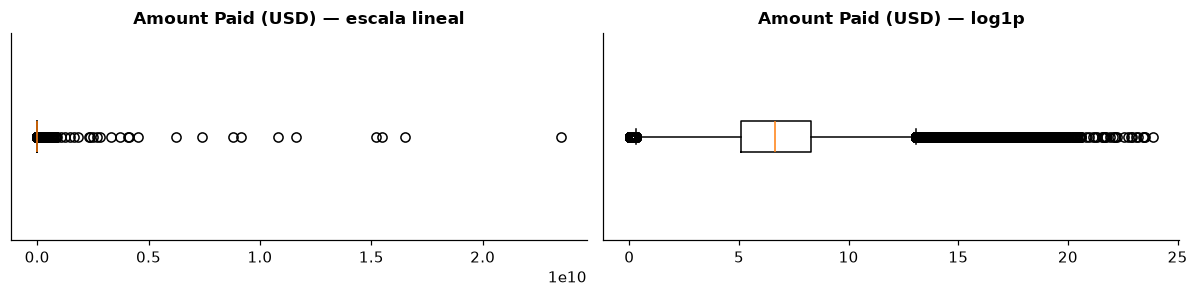

In [7]:
def marcar_atipicos(df: pd.DataFrame) -> pd.DataFrame:
    """IQR sobre log1p(monto) por moneda. En escala lineal, la cola larga haría que casi todo pareciera atípico."""
    df = df.copy()
    lg = np.log1p(df["Amount Paid"])
    g = lg.groupby(df["Payment Currency"])
    q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
    iqr = q3 - q1
    df["monto_atipico"] = ((lg < q1 - 1.5 * iqr) | (lg > q3 + 1.5 * iqr)).astype("int8")
    return df

df_proceso = marcar_atipicos(df_proceso)

n = int(df_proceso["monto_atipico"].sum())
print(f"Atípicos marcados: {n:,} ({100 * n / len(df_proceso):.2f} %)")
print(f"Amount Paid · mediana {df_proceso['Amount Paid'].median():,.2f} · máximo {df_proceso['Amount Paid'].max():,.0f}")

usd = df_proceso.loc[df_proceso["Payment Currency"] == "US Dollar", "Amount Paid"]
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].boxplot(usd, orientation="horizontal"); ax[0].set_title("Amount Paid (USD) — escala lineal")
ax[1].boxplot(np.log1p(usd), orientation="horizontal"); ax[1].set_title("Amount Paid (USD) — log1p")
for a in ax:
    a.set_yticks([])
plt.tight_layout(); plt.show()

**Decisión: conservar y marcar.** Los atípicos se detectan con IQR sobre `log1p(monto)` dentro de cada moneda y se registran en `monto_atipico`, sin eliminarlos. En lavado de activos, un monto extremo puede ser precisamente la señal buscada: borrarlo eliminaría casos positivos. Para que no dominen un modelo, se comprimen con `log1p` en la sección 2.3.

*Limitación:* sin validar contra la fuente, no se puede distinguir un error de captura de una operación real.

---
## 2. Transformación y codificación

### 2.1 Conversión de tipos

In [8]:
FORMATOS_FECHA = ["%Y/%m/%d %H:%M", "%d-%m-%Y %H:%M", "%Y-%m-%dT%H:%M:%S"]   # oficial + alternativos

def convertir_tipos(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    t = pd.to_datetime(df["Timestamp"], format=FORMATOS_FECHA[0], errors="coerce")
    for f in FORMATOS_FECHA[1:]:
        t = t.fillna(pd.to_datetime(df["Timestamp"], format=f, errors="coerce"))
    df["Timestamp"] = t
    df = df.dropna(subset=["Timestamp"])                       # fecha irrecuperable
    for c in ["From Bank", "To Bank"]:
        df[c] = pd.to_numeric(df[c]).astype("int64")
    return df.reset_index(drop=True)

cols = ["Timestamp", "From Bank", "To Bank", "Amount Paid"]
tipos_antes = df_proceso[cols].dtypes.astype(str)
n0 = len(df_proceso)
df_proceso = convertir_tipos(df_proceso)

display(pd.DataFrame({"antes": tipos_antes, "después": df_proceso[cols].dtypes.astype(str)}))
print(f"Filas con fecha inválida o nula eliminadas: {n0 - len(df_proceso):,}")
print(f"Rango temporal: {df_proceso['Timestamp'].min()} → {df_proceso['Timestamp'].max()}")

,antes,después
Timestamp,str,datetime64[us]
From Bank,str,int64
To Bank,str,int64
Amount Paid,float64,float64


Filas con fecha inválida o nula eliminadas: 14,125
Rango temporal: 2022-09-04 13:00:00 → 2022-09-13 16:09:00


`Timestamp` llegaba como texto en tres formatos distintos: se prueban en orden y se descarta solo lo irrecuperable. `Amount Paid` ya quedó en `float64` en la sección 1.3.

### 2.2 Codificación categórica

In [9]:
def codificar(df: pd.DataFrame) -> pd.DataFrame:
    return pd.concat([df, pd.get_dummies(df["Payment Format"], prefix="fmt", dtype="int8")], axis=1)

df_proceso = codificar(df_proceso)
dummies = df_proceso.filter(like="fmt_")
display(dummies.head())
display(dummies.sum().rename("transacciones").to_frame())
assert (dummies.sum(axis=1) == 1).all()        # cada transacción activa exactamente un indicador

,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire
0,0,0,0,0,1,0,0
1,0,0,0,1,0,0,0
2,0,0,0,1,0,0,0
3,0,0,0,0,1,0,0
4,0,0,0,1,0,0,0


,transacciones
fmt_ACH,107770
fmt_Bitcoin,41075
fmt_Cash,92714
fmt_Cheque,359157
fmt_Credit Card,265335
fmt_Desconocido,47336
fmt_Wire,32814


**Técnica: One-Hot.** `Payment Format` es una variable nominal (no hay orden entre Cheque, Wire y ACH) y de baja cardinalidad: 6 valores en esta ventana más `Desconocido`. Una codificación ordinal inventaría un orden que no existe.

Las monedas (15 valores) no se codifican una por una: se resumen en `misma_moneda` en la sección 3.

### 2.3 Escalamiento

,Amount Paid (antes),monto_z (después)
count,"946,201.000","946,201.000"
mean,"8,870,261.385",-0.000
std,"2,341,234,766.984",1.000
min,0.000,-2.188
25%,180.550,-0.613
50%,"1,221.790",-0.035
75%,"9,268.550",0.579
max,"1,727,505,625,070.000",6.347


Asimetría: 576.3 → 0.27


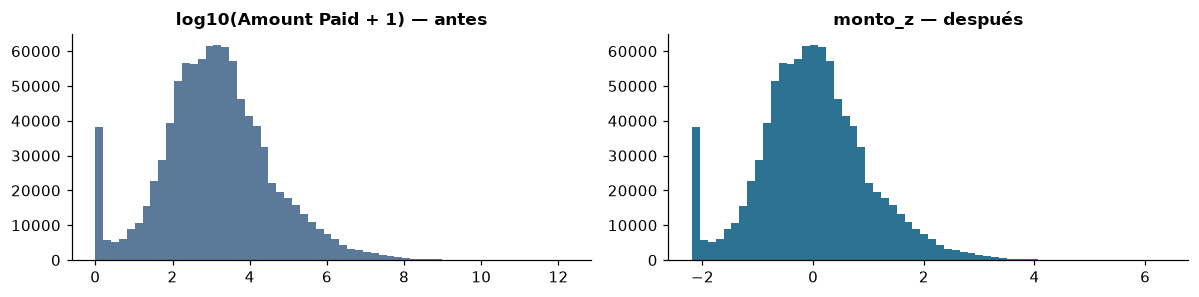

In [10]:
def escalar(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["log_monto_pagado"] = np.log1p(df["Amount Paid"])
    df["monto_z"] = (df["log_monto_pagado"] - df["log_monto_pagado"].mean()) / df["log_monto_pagado"].std()
    return df

antes = df_proceso["Amount Paid"]
df_proceso = escalar(df_proceso)

display(pd.DataFrame({"Amount Paid (antes)": antes.describe(), "monto_z (después)": df_proceso["monto_z"].describe()}))
print(f"Asimetría: {antes.skew():,.1f} → {df_proceso['monto_z'].skew():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].hist(np.log10(antes + 1), bins=60, color="#5b7a99"); ax[0].set_title("log10(Amount Paid + 1) — antes")
ax[1].hist(df_proceso["monto_z"], bins=60, color="#2c7293"); ax[1].set_title("monto_z — después")
plt.tight_layout(); plt.show()

**Técnica: `log1p` + Z-score.** El monto tiene una asimetría extrema: la mediana está en miles y los máximos en billones. `log1p` comprime la cola y el Z-score deja la variable con media 0 y desviación 1, en una escala comparable con las binarias. Se descartó Min-Max porque los máximos aplastarían el resto de los valores.

*Nota:* la media y la desviación se calculan sobre toda la muestra. Al modelar, deben ajustarse solo con el conjunto de entrenamiento.

---
## 3. Ingeniería de características

| Variable | Origen | Fórmula | Interpretación | Utilidad |
|---|---|---|---|---|
| `misma_moneda` | `Receiving Currency`, `Payment Currency` | `1` si ambas coinciden | `0` = hubo conversión de divisa | Resume dos categóricas de 15 valores en un binario; los cruces de moneda son un patrón habitual de lavado |
| `hora` | `Timestamp` | `Timestamp.dt.hour` (0–23) | Hora del día de la operación | El timestamp completo no generaliza; la hora captura patrones de actividad |

In [11]:
def crear_variables(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["misma_moneda"] = (df["Receiving Currency"] == df["Payment Currency"]).astype("int8")
    df["hora"] = df["Timestamp"].dt.hour.astype("int8")
    return df

df_proceso = crear_variables(df_proceso)

def tasa_por(col: str) -> pd.DataFrame:
    return (df_proceso.groupby(col)["Is Laundering"]
            .agg(transacciones="count", tasa_lavado="mean")
            .assign(tasa_lavado=lambda d: 100 * d["tasa_lavado"]))

display(df_proceso[["Receiving Currency", "Payment Currency", "misma_moneda"]].head())
display(tasa_por("misma_moneda").rename(columns={"tasa_lavado": "tasa de lavado (%)"}))

,Receiving Currency,Payment Currency,misma_moneda
0,US Dollar,US Dollar,1
1,US Dollar,US Dollar,1
2,US Dollar,US Dollar,1
3,US Dollar,US Dollar,1
4,US Dollar,US Dollar,1


,transacciones,tasa de lavado (%)
misma_moneda,,
0,14875,0.000
1,931326,0.070


### 3.1 Señal de `hora`

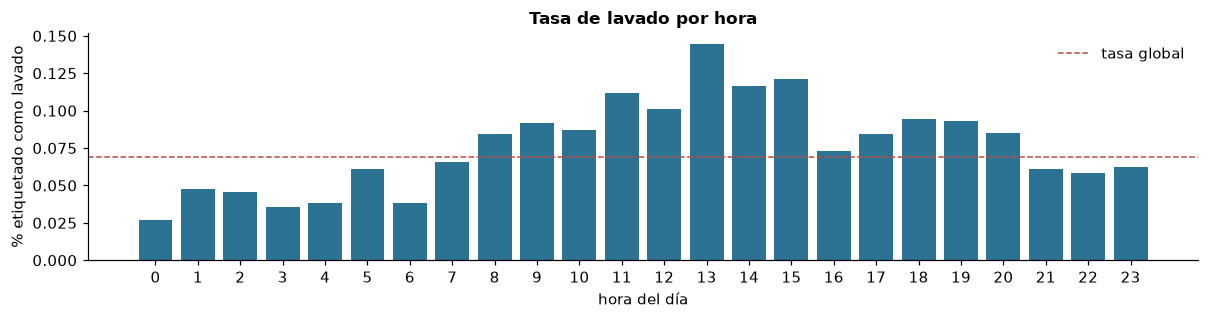

In [12]:
por_hora = tasa_por("hora")
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(por_hora.index, por_hora["tasa_lavado"], color="#2c7293")
ax.axhline(100 * df_proceso["Is Laundering"].mean(), color="#b85042", ls="--", lw=1, label="tasa global")
ax.set_xticks(range(24)); ax.set_xlabel("hora del día"); ax.set_ylabel("% etiquetado como lavado")
ax.set_title("Tasa de lavado por hora"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

La tasa de lavado cambia a lo largo del día: es más alta entre las 11 y las 15 h y más baja de madrugada. Por eso `hora` aporta información que no está en las demás variables.

---
## 4. Selección de variables

In [13]:
EXCLUIR = ["Timestamp", "From Bank", "To Bank", "Account", "Account.1", "Amount Received",
           "Receiving Currency", "Payment Currency", "Payment Format", "Amount Paid", "log_monto_pagado"]

def seleccionar(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop(columns=EXCLUIR)

MOTIVO = {
    "Timestamp": "reemplazada por hora", "Amount Paid": "reemplazada por monto_z",
    "log_monto_pagado": "paso intermedio de monto_z", "Payment Format": "reemplazada por fmt_*",
    "Receiving Currency": "reemplazada por misma_moneda", "Payment Currency": "reemplazada por misma_moneda",
    "Amount Received": "redundante con Amount Paid",
    "From Bank": "identificador", "To Bank": "identificador", "Account": "identificador", "Account.1": "identificador",
}
decision = pd.DataFrame({"decisión": ["excluir" if c in EXCLUIR else "conservar" for c in df_proceso.columns],
                         "motivo": [MOTIVO.get(c, "objetivo" if c == "Is Laundering" else "predictora")
                                    for c in df_proceso.columns]},
                        index=df_proceso.columns).sort_values("decisión")
display(decision)

,decisión,motivo
monto_atipico,conservar,predictora
monto_z,conservar,predictora
fmt_Wire,conservar,predictora
fmt_Desconocido,conservar,predictora
fmt_Credit Card,conservar,predictora
fmt_Cheque,conservar,predictora
fmt_Cash,conservar,predictora
fmt_Bitcoin,conservar,predictora
fmt_ACH,conservar,predictora
misma_moneda,conservar,predictora


### Revisión de fuga de información (data leakage)

- **`Is Laundering`** es la etiqueta y se usa solo como objetivo, nunca como predictora. Ninguna otra columna se conoce después del evento.
- **Cuentas y bancos** se excluyen por ser identificadores de alta cardinalidad: un modelo memorizaría cuentas concretas en lugar de patrones.
- **`Amount Received`** es casi redundante con `Amount Paid`.
- **Escalado:** al modelar, la media y la desviación se ajustan solo con el conjunto de entrenamiento.

---
## 5. Dataset en proceso

Versión intermedia: conserva las columnas originales ya limpias junto a las derivadas, para auditar cada transformación.

In [14]:
df_proceso.to_csv(DESTINO["proceso"] / "dataset_proceso.csv", index=False)   # entregable 2

print(f"Dimensiones: {df_proceso.shape[0]:,} filas × {df_proceso.shape[1]} columnas")
print(f"Nulos: {int(df_proceso.isna().sum().sum())} · Duplicados exactos: {int(df_proceso.duplicated().sum())}")
display(df_proceso.head())
display(df_proceso.dtypes.astype(str).value_counts().rename("columnas").to_frame())

Dimensiones: 946,201 filas × 23 columnas


Nulos: 0 · Duplicados exactos: 1


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,monto_atipico,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire,log_monto_pagado,monto_z,misma_moneda,hora
0,2022-09-04 13:17:00,123807,811EFB390,18747,81B8AC220,"5,604.040",US Dollar,"5,604.040",US Dollar,Credit Card,0,0,0,0,0,0,1,0,0,8.631,0.426,1,13
1,2022-09-04 13:16:00,70,10042B660,74853,81B9F6110,"62,961.100",US Dollar,"62,961.100",US Dollar,Cheque,0,0,0,0,0,1,0,0,0,11.050,1.159,1,13
2,2022-09-04 13:03:00,221024,817C39630,70701,81B15C870,"2,268.050",US Dollar,"2,268.050",US Dollar,Cheque,0,0,0,0,0,1,0,0,0,7.727,0.152,1,13
3,2022-09-04 13:18:00,221024,817C39630,70701,81B15C870,"2,569.930",US Dollar,"2,569.930",US Dollar,Credit Card,0,0,0,0,0,0,1,0,0,7.852,0.190,1,13
4,2022-09-04 13:29:00,226290,80C0B9770,58500,81BB1DE90,"65,406.670",US Dollar,"65,406.670",US Dollar,Cheque,0,0,0,0,0,1,0,0,0,11.088,1.171,1,13


,columnas
int8,10
str,5
float64,4
int64,3
datetime64[us],1


El único duplicado exacto restante aparece porque, al normalizar, dos filas que diferían solo en la grafía quedaron iguales.

---
## 6. Pipeline reproducible

`preparar_datos` encadena las mismas funciones de las secciones 1 a 4. A partir del original reconstruye el dataset final sin pasos manuales.

In [15]:
PASOS = [limpiar_nulos, quitar_duplicados, normalizar, marcar_atipicos,   # 1. limpieza
         convertir_tipos,                                                 # 2.1 tipos
         codificar, escalar,                                              # 2.2–2.3 transformación
         crear_variables,                                                 # 3. características
         seleccionar]                                                     # 4. selección

def preparar_datos(df: pd.DataFrame) -> pd.DataFrame:
    """Original → dataset final. No modifica el DataFrame de entrada."""
    df = df.copy()
    for paso in PASOS:
        df = paso(df)
    return df

df_final_reproducible = preparar_datos(df_original)
print(f"Pipeline ejecutado desde el original: {df_final_reproducible.shape}")

Pipeline ejecutado desde el original: (946201, 12)


---
## 7. Dataset final

### 7.1 Construcción y verificación de reproducibilidad

In [16]:
df_final = seleccionar(df_proceso)
pd.testing.assert_frame_equal(df_final_reproducible, df_final)
print("Verificado: el pipeline reproduce exactamente el dataset final.")

Verificado: el pipeline reproduce exactamente el dataset final.


### 7.2 Validación

In [17]:
assert df_final.isna().sum().sum() == 0, "hay nulos en el dataset final"
assert all(pd.api.types.is_numeric_dtype(t) for t in df_final.dtypes), "hay columnas no numéricas"

print(f"Dimensiones: {df_final.shape[0]:,} filas × {df_final.shape[1]} columnas")
print(f"Nulos: 0 · Duplicados en las columnas finales: {int(df_final.duplicated().sum()):,}")
display(pd.DataFrame({"tipo": df_final.dtypes.astype(str), "mín": df_final.min(), "máx": df_final.max()}))
display(df_final.head())

Dimensiones: 946,201 filas × 12 columnas


Nulos: 0 · Duplicados en las columnas finales: 42,276


,tipo,mín,máx
Is Laundering,int64,0.000,1.000
monto_atipico,int8,0.000,1.000
fmt_ACH,int8,0.000,1.000
fmt_Bitcoin,int8,0.000,1.000
fmt_Cash,int8,0.000,1.000
fmt_Cheque,int8,0.000,1.000
fmt_Credit Card,int8,0.000,1.000
fmt_Desconocido,int8,0.000,1.000
fmt_Wire,int8,0.000,1.000
monto_z,float64,-2.188,6.347


,Is Laundering,monto_atipico,fmt_ACH,fmt_Bitcoin,fmt_Cash,fmt_Cheque,fmt_Credit Card,fmt_Desconocido,fmt_Wire,monto_z,misma_moneda,hora
0,0,0,0,0,0,0,1,0,0,0.426,1,13
1,0,0,0,0,0,1,0,0,0,1.159,1,13
2,0,0,0,0,0,1,0,0,0,0.152,1,13
3,0,0,0,0,0,0,1,0,0,0.190,1,13
4,0,0,0,0,0,1,0,0,0,1.171,1,13


Los duplicados del dataset final **no se eliminan**. Al quitar identificadores y timestamp, transacciones distintas pueden coincidir en las 12 variables conservadas, pero siguen siendo operaciones diferentes.

### 7.3 Comparación original → proceso → final

In [18]:
def resumen_dataset(df: pd.DataFrame, nombre: str) -> dict:
    return {"dataset": nombre, "filas": len(df), "columnas": df.shape[1],
            "nulos": int(df.isna().sum().sum()), "duplicados": int(df.duplicated().sum()),
            "numéricas": df.select_dtypes(include=np.number).shape[1],
            "no numéricas": df.select_dtypes(exclude=np.number).shape[1],
            "positivos": int(df["Is Laundering"].sum()),
            "% positivos": round(100 * df["Is Laundering"].mean(), 4)}

comparacion = pd.DataFrame([resumen_dataset(df_original, "original"),
                            resumen_dataset(df_proceso, "proceso"),
                            resumen_dataset(df_final, "final")]).set_index("dataset")
display(comparacion.style.format(thousands=".", precision=4))

,filas,columnas,nulos,duplicados,numéricas,no numéricas,positivos,% positivos
dataset,,,,,,,,
original,1.020.000,11,160.369,20.002,1,10,704,0.0690
proceso,946.201,23,0,1,17,6,655,0.0692
final,946.201,12,0,42.276,12,0,655,0.0692


### 7.4 Exportación y verificación de entregables

In [19]:
df_final.to_csv(DESTINO["final"] / "dataset_final.csv", index=False)   # entregable 3

entregables = [DESTINO["original"] / "dataset_original.csv",
               DESTINO["proceso"] / "dataset_proceso.csv",
               DESTINO["final"] / "dataset_final.csv"]
display(pd.DataFrame({"archivo": [p.name for p in entregables],
                      "carpeta": [p.parent.name for p in entregables],
                      "tamaño": [f"{p.stat().st_size / 1e6:,.1f} MB" for p in entregables]}).set_index("archivo"))
assert all(p.exists() for p in entregables)

,carpeta,tamaño
archivo,,
dataset_original.csv,01_original,93.7 MB
dataset_proceso.csv,02_proceso,143.9 MB
dataset_final.csv,03_final,39.9 MB


---
## 8. Conclusiones

1. **Problemas principales:** nulos reales y disfrazados (`?`, `-`), duplicados exactos, categorías con múltiples grafías, montos como texto (`$`, coma europea, negativos), fechas en formatos mezclados y montos extremos.
2. **Transformaciones de mayor impacto:** la normalización de montos y categorías, que recupera el tipo numérico y reduce 25 formatos de pago a 7, y `log1p` + Z-score, que lleva la asimetría del monto de 576 a 0,27.
3. **Variables nuevas:** `misma_moneda`, `hora`, `monto_atipico`, `monto_z` y los indicadores `fmt_*`.
4. **Variables descartadas:** identificadores (cuentas, bancos), `Timestamp`, `Amount Received` y las columnas originales ya reemplazadas por derivadas.
5. **¿Listo para modelar?** Sí: 946.201 filas, 12 variables numéricas, sin nulos y reproducible con `preparar_datos`. `Is Laundering` queda como objetivo y conserva su proporción (0,069 %).
6. **Limitaciones:**
   - El desbalance extremo exige estratificar y evaluar con recall, precisión y PR-AUC.
   - Se trabajó con una ventana de la fuente, no con el archivo completo.
   - El escalado está ajustado sobre toda la muestra.
   - Los atípicos se conservaron sin distinguir error de señal.